In [1]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib import rcParams, colors
from matplotlib import ticker as mticker
import geopandas as gpd
rcParams.update({'figure.autolayout': False})
import os
import wrf
import cmcrameri as cm
#import pymannkendall as mk
from cartopy import crs as ccrs
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
from shapely.geometry import mapping
import glob
import pandas as pd
import pickle
import dask
import rioxarray
import xesmf as xe
import dask
from dask.distributed import Client, LocalCluster
from dask import delayed
import dask.array as da
from dask_jobqueue import PBSCluster
import xarray as xr
from concurrent.futures import ProcessPoolExecutor
import calendar
import zarr
import h5netcdf

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=1,  # Total number of cores across all processes
    memory='300GB',  # Memory per worker
    processes=10,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=300GB',  # Resources per worker
    account='UCOR0077',  # Project ID
    walltime='6:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 40267 instead
  warnings.warn(


In [7]:
client

<Client: 'tcp://128.117.208.179:39869' processes=10 threads=10, memory=279.40 GiB>

In [8]:
ds_t2_full = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc', chunks='auto')
ds_da_full = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/MSL_1950/dyn_adj_ERA5_India_50_34_20_74.nc', chunks='auto')

ds_t2_uf = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc', chunks='auto')
ds_da_uf = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/L1/dyn_adj/dyn_adj_ERA5_India_50_34_20_74.nc', chunks='auto')

ds_t2_masked_full = ds_t2_full.sel(time=ds_da_full.time, lat=ds_da_full.lat, lon=ds_da_full.lon)
ds_t2_masked_uf = ds_t2_uf.sel(time=ds_da_uf.time, lat=ds_da_uf.lat, lon=ds_da_uf.lon)
ds_t2_masked = ds_t2_masked_full - ds_t2_masked_uf
ds_t2 = ds_t2_masked['anom']


ds_da = ds_da_full['dynamic'] - ds_da_uf['dynamic']
ds_da = dask.compute(ds_da)[0]

ds_diff = (ds_t2_full['anom']-ds_da_full['dynamic']) - (ds_t2_uf['anom']-ds_da_uf['dynamic'])
ds_diff = dask.compute(ds_diff)[0]


ds_msl_full = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/MSL_ERA5_India_AMJJAS_anom.nc', chunks='auto')
ds_msl_uf = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/AMJJAS_anom/MSL_ERA5_India_AMJJAS_anom.nc', chunks='auto')
ds_msl = ds_msl_full - ds_msl_uf

In [9]:
a = ['#eff3ff','#bdd7e7','#6baed6','#3182bd','#08519c']
a[::-1]

['#08519c', '#3182bd', '#6baed6', '#bdd7e7', '#eff3ff']

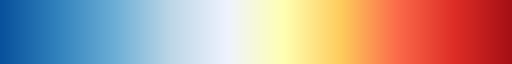

In [10]:
from matplotlib.colors import LinearSegmentedColormap
combined_colors = ['#08519c', '#3182bd', '#6baed6', '#bdd7e7', '#eff3ff','#ffffb2','#fecc5c','#fb6a4a','#de2d26','#a50f15']
def create_gradient_colormap(n_colors, color_list=combined_colors):
    return LinearSegmentedColormap.from_list("custom_gradient", color_list, N=n_colors)
cmap1 = create_gradient_colormap(256,combined_colors)
cmap1

In [18]:
def plot_simulated(llon,llat,prec,row,col,levs,cmap1,shape_feature,ax1):
    #plt.style.use('classic')
    #plt.title(title)
    #ax1.("Y - axis")
    s=ax1.axes
    g=s.gridlines()
    g.bottom_labels=False
    g.left_labels=True

    if row == 0:
        g.bottom_labels=True
    if col>0:
        g.left_labels=False
    g.ylines=False
    g.xlines=False
    #g.xlocator = mticker.FixedLocator(np.arange(-115,-99,7))
    #g.ylocator = mticker.FixedLocator(np.arange(30,50,5))
    g.xformatter = LONGITUDE_FORMATTER
    g.yformatter = LATITUDE_FORMATTER
    g.xlabel_style = {'size':7.5, 'color': 'k'}
    g.ylabel_style = {'size': 7.5, 'color': 'k'}  
    pc1 = plt.contourf(llon,llat,prec,cmap=cmap1,transform=ccrs.PlateCarree(), levels=levs, extend='both')   
    #pc1 = plt.contourf(llon,llat,prec,colors=cmap1,transform=ccrs.PlateCarree(), levels=levs)   
    #fname = '/media/ankur/f764cec3-536e-4e1d-b58c-9442c881e0a0/ankur/VIC_DATA/BasinBoundary/Beas.shp'
    
    ax1.add_feature(shape_feature, edgecolor='k', lw=0.75)
    return pc1


In [19]:
times = slice('2024-05-25','2024-06-01')

In [20]:
import matplotlib.patches as patches

<xarray.DataArray 'anom' ()> Size: 8B
array(-1.25646929)
<xarray.DataArray 'dynamic' ()> Size: 8B
array(-1.39510495)
<xarray.DataArray ()> Size: 8B
array(0.13863566)


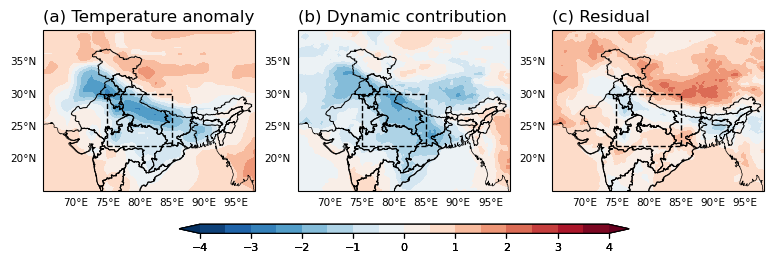

In [21]:
f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 3)
gs1.update(left=0.099,  bottom=0.14, wspace=0.2 ,hspace=0.16)

levs = np.arange(-4,4.1,0.5)
levdiff = np.arange(-4,4.1,0.2)
c1diff =  cmap1
c1 = 'RdBu_r'#cmap
months=[5,6]

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)

datalist = [ds_t2,ds_da,ds_diff]
panel_title = ['(a) Temperature anomaly', '(b) Dynamic contribution', '(c) Residual']

for i in range(3):
    
    ax1 = f.add_subplot(gs1[0,i],projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    data = datalist[i]
    data = data.sel(time=times).mean(dim='time')
    pc = plot_simulated(data.lon,data.lat,data,0,0,levs,c1,shape_feature,ax1)
    #plt.title("Maximum Heatwave Duration: 2024 : "+''.join(map(str, months)))
    ax1.set_xlim([65,98])
    ax1.set_ylim([15,40])
    ax1.set_title(panel_title[i],loc='left')
    cbar_ax = f.add_axes([0.25, 0.1,0.5, 0.03])
    cb = plt.colorbar(pc, cax=cbar_ax,orientation="horizontal")
    cb.ax.tick_params(labelsize=8)

    msl_data = ds_msl['anom'].sel(time=times).std(dim='time')
    
    box_lon = slice(75, 85)
    box_lat = slice(30, 22)
    box_mean = data.sel(lon=box_lon, lat=box_lat).mean()
    print(box_mean.compute())
    #neg_levels = np.linspace(np.min(msl_data), 0, 50, endpoint=False)
    #pos_levels = np.linspace(0, np.max(msl_data), 50, endpoint=False)[1:]

    #ax1.contour(msl_data.lon,msl_data.lat,msl_data,levels=np.arange(-200,101,50),cmap='RdBu_r', lw=1)
    #ax1.contour(msl_data,levels=pos_levels, colors='red', linestyles='dashed', add_labels=True)

    
    #cb.ax.set_title('Duration',fontsize=9)
    #rectangle1 = patches.Rectangle((70, 22), 5, 8, edgecolor='b', facecolor='none', linewidth=1, linestyle='--')
    rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    
    # Add the rectangle to the plot
    #ax1.add_patch(rectangle1)
    ax1.add_patch(rectangle2)
plt.savefig("Fig1-event1_forced.pdf",dpi=300,format='pdf',transparent=True)

In [22]:
data.sel(lon=box_lon, lat=box_lat)

<xarray.DataArray (lat: 33, lon: 41)> Size: 11kB
array([[-0.8730184 , -0.87224968, -0.83401694, ...,  1.8660208 ,
         1.84816385,  1.88023294],
       [-0.83826821, -0.82606688, -0.77894243, ...,  2.00027952,
         2.05620823,  2.13372515],
       [-0.69135954, -0.70255387, -0.68168816, ...,  1.80703703,
         1.96931282,  2.04221718],
       ...,
       [ 0.33674392,  0.20367191,  0.06987676, ...,  0.74945454,
         0.82506096,  0.74333786],
       [ 0.51089115,  0.36229745,  0.22235082, ...,  0.61106424,
         0.72499736,  0.65468369],
       [ 0.69401527,  0.58196579,  0.48033694, ...,  0.4850058 ,
         0.69793234,  0.67908553]])
Coordinates:
  * lat      (lat) float64 264B 30.0 29.75 29.5 29.25 ... 22.75 22.5 22.25 22.0
  * lon      (lon) float64 328B 75.0 75.25 75.5 75.75 ... 84.25 84.5 84.75 85.0

In [23]:
times = slice('2024-06-10','2024-06-20')

<xarray.DataArray 'anom' ()> Size: 8B
array(-0.34541004)
<xarray.DataArray 'dynamic' ()> Size: 8B
array(-0.3457271)
<xarray.DataArray ()> Size: 8B
array(0.00031706)


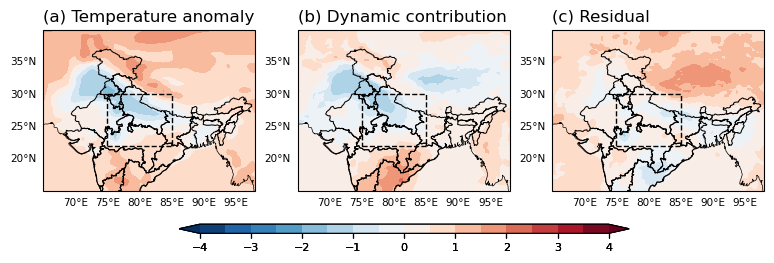

In [24]:
f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 3)
gs1.update(left=0.099,  bottom=0.14, wspace=0.2 ,hspace=0.16)

levs = np.arange(-4,4.1,0.5)
levdiff = np.arange(-4,4.1,0.2)
c1diff =  cmap1
c1 = 'RdBu_r'#cmap
months=[5,6]

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)

datalist = [ds_t2,ds_da,ds_diff]
panel_title = ['(a) Temperature anomaly', '(b) Dynamic contribution', '(c) Residual']

for i in range(3):
    
    ax1 = f.add_subplot(gs1[0,i],projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    data = datalist[i]
    data = data.sel(time=times).mean(dim='time')
    pc = plot_simulated(data.lon,data.lat,data,0,0,levs,c1,shape_feature,ax1)
    ax1.set_title(panel_title[i],loc='left')
    #plt.title("Maximum Heatwave Duration: 2024 : "+''.join(map(str, months)))
    ax1.set_xlim([65,98])
    ax1.set_ylim([15,40])
    cbar_ax = f.add_axes([0.25, 0.1,0.5, 0.03])
    cb = plt.colorbar(pc, cax=cbar_ax,orientation="horizontal")
    cb.ax.tick_params(labelsize=8)
    box_lon = slice(75, 85)
    box_lat = slice(30, 22)
    box_mean = data.sel(lon=box_lon, lat=box_lat).mean()
    print(box_mean.compute())
    
    #cb.ax.set_title('Duration',fontsize=9)
    #rectangle1 = patches.Rectangle((70, 22), 5, 8, edgecolor='b', facecolor='none', linewidth=1, linestyle='--')
    rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    
    # Add the rectangle to the plot
    #ax1.add_patch(rectangle1)
    ax1.add_patch(rectangle2)
plt.savefig("Fig1-event2_forced.pdf",dpi=300,format='pdf',transparent=True)

In [29]:
data

<xarray.DataArray (lat: 361, lon: 321)> Size: 927kB
array([[0.19926621, 0.20501207, 0.21103559, ..., 0.32300743, 0.32325359,
        0.32423576],
       [0.18640499, 0.19369256, 0.20244393, ..., 0.33235848, 0.33010625,
        0.32757233],
       [0.1843027 , 0.18984043, 0.1937973 , ..., 0.33603599, 0.33480196,
        0.33442738],
       ...,
       [0.42425558, 0.41698485, 0.44110178, ..., 0.1818348 , 0.21855045,
        0.28168991],
       [0.37189213, 0.40616037, 0.42016852, ..., 0.18739473, 0.16666512,
        0.17526527],
       [0.36419484, 0.39200978, 0.42456562, ..., 0.30376524, 0.28186226,
        0.1594819 ]])
Coordinates:
  * lat      (lat) float64 3kB 80.0 79.75 79.5 79.25 ... -9.25 -9.5 -9.75 -10.0
  * lon      (lon) float64 3kB 40.0 40.25 40.5 40.75 ... 119.2 119.5 119.8 120.0